In [19]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

PROJECT_ROOT = Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data import load_german_credit

sns.set_theme(style="whitegrid")

df = load_german_credit()

# Exploratory Data Analysis

### Basic dataset inspection
Verifying that there are no missing values and understanding the numerical attributes

In [12]:
print("Shape:", df.shape)
print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isna().sum().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nNumerical statistics:")
print(df.describe())

Shape: (1000, 29)

Data types:
checking_account                str
duration_months               int64
credit_history                  str
purpose                         str
credit_amount                 int64
savings_account                 str
employment_since                str
installment_rate              int64
personal_status_sex             str
other_debtors                   str
residence_since               int64
property                        str
age                           int64
other_installment_plans         str
housing                         str
existing_credits              int64
job                             str
liable_people                 int64
telephone                       str
foreign_worker                  str
class_label                   int64
job_label                       str
housing_label                   str
credit_history_label            str
savings_account_label           str
purpose_label                   str
sex                             s

### Target distribution
The target value is moderately imbalanced: 70% good credit risk and 30% bad

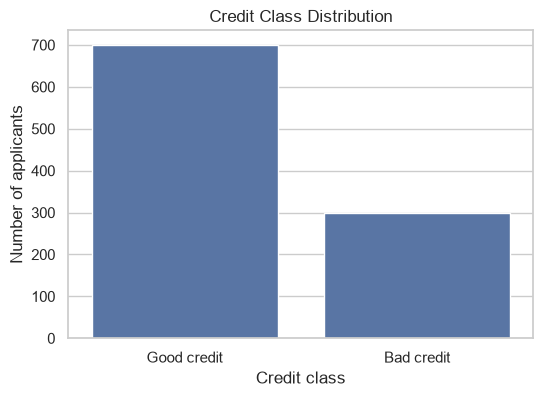

In [13]:
target_counts = df["target_bad"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(x=["Good credit", "Bad credit"], y=target_counts.values, ax=ax)

ax.set_title("Credit Class Distribution")
ax.set_xlabel("Credit class")
ax.set_ylabel("Number of applicants")

plt.show()

### Inspecting sensitive and proxy features
For each feature, calculate the number of applicants and the proportion classified as bad credit.

In [18]:
sensitive_features = ["sex", "age_group"]

proxy_features = [
    "job",
    "housing",
    "credit_history",
    "savings_account",
    "purpose",
]

proxy_labels = [
    "job_label",
    "housing_label",
    "credit_history_label",
    "savings_account_label",
    "purpose_label",
]

for feature in sensitive_features:
    summary = (
        df.groupby(feature, observed=True)["target_bad"]
        .agg(applicants="count", bad_credit_rate="mean")
        .sort_values("applicants", ascending=False)
    )

    summary["applicant_percentage"] = summary["applicants"] / len(df) * 100

    print(f"\n=== {feature} ===")
    print(summary.round(3))

for feature, label in zip(proxy_features, proxy_labels):
    summary = (
        df.groupby([feature, label], observed=True)["target_bad"]
        .agg(applicants="count", bad_credit_rate="mean")
        .reset_index()
        .sort_values("applicants", ascending=False)
    )

    summary["applicant_percentage"] = summary["applicants"] / len(df) * 100

    print(f"\n=== {feature} ===")
    print(summary.round(3).to_string(index=False))


=== sex ===
        applicants  bad_credit_rate  applicant_percentage
sex                                                      
male           690            0.277                  69.0
female         310            0.352                  31.0

=== age_group ===
           applicants  bad_credit_rate  applicant_percentage
age_group                                                   
>=30              629            0.259                  62.9
<30               371            0.369                  37.1

=== job ===
 job                                     job_label  applicants  bad_credit_rate  applicant_percentage
A173                   Skilled employee / official         630            0.295                  63.0
A172                          Unskilled (resident)         200            0.280                  20.0
A174 Management / self-employed / highly qualified         148            0.345                  14.8
A171         Unemployed / unskilled (non-resident)          22         

Here, each feature is divided into its categories, with good-credit and bad-credit applicants shown separately.

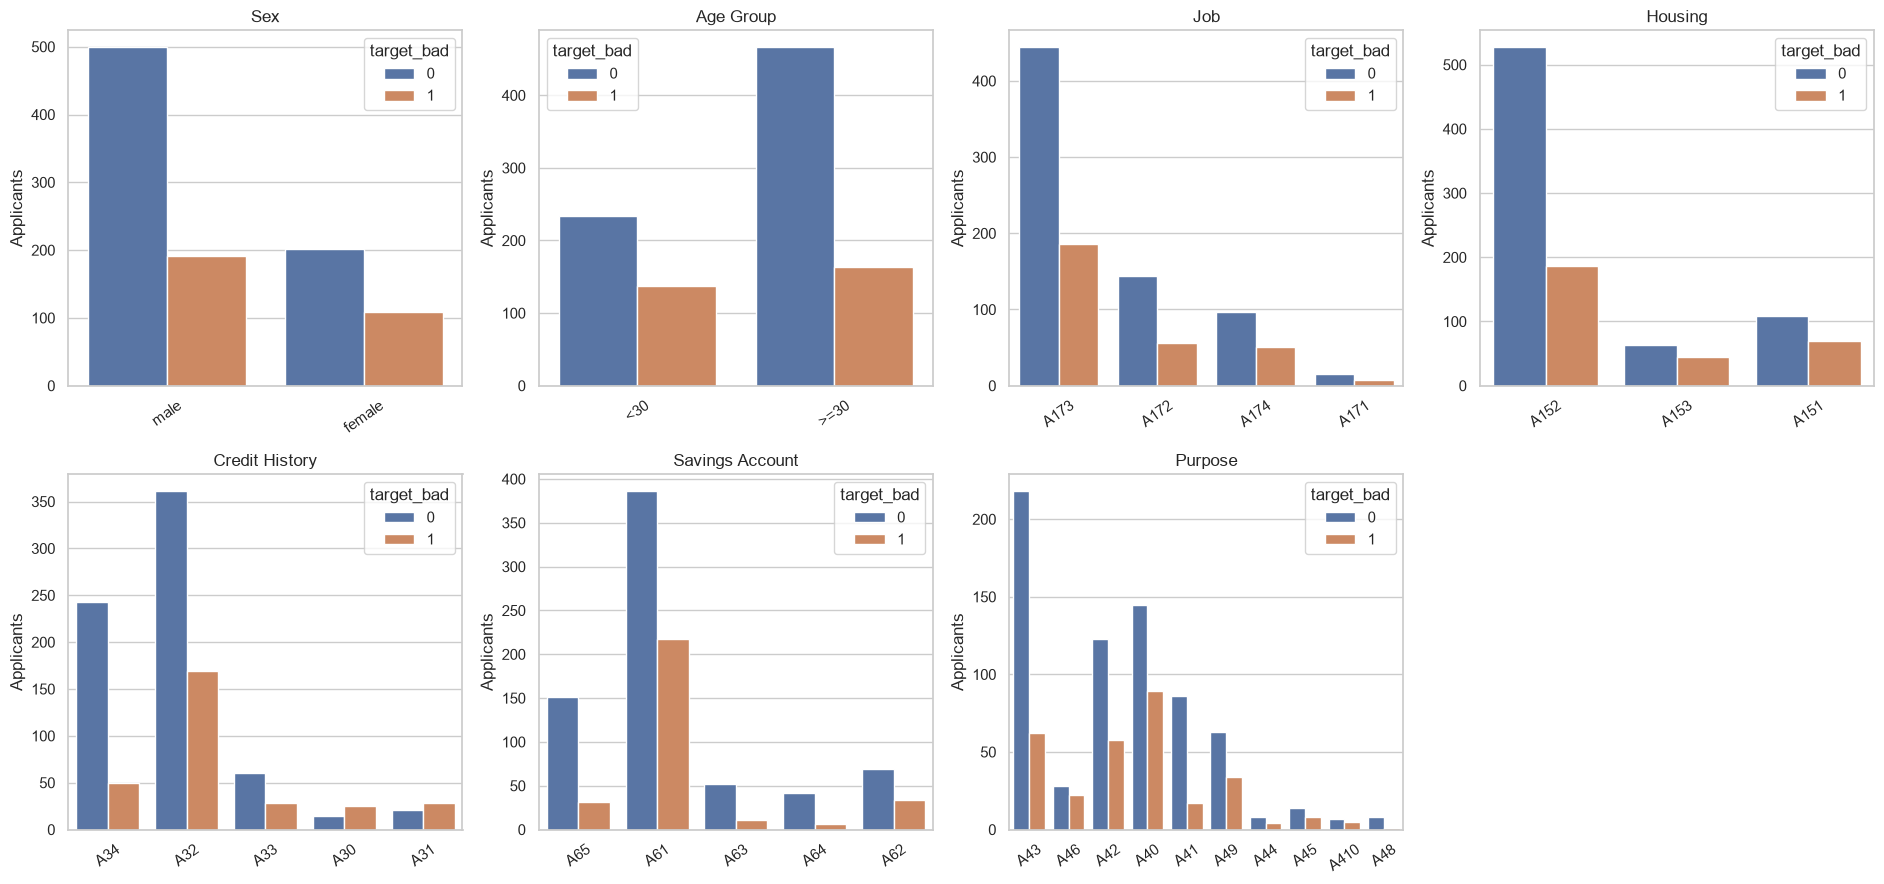

In [19]:
fig, axes = plt.subplots(2, 4, figsize=(19, 9))
axes = axes.flatten()
selected_features = sensitive_features + proxy_features

for ax, feature in zip(axes, selected_features):
    sns.countplot(
        data=df,
        x=feature,
        hue="target_bad",
        ax=ax,
    )
    ax.set_title(feature.replace("_", " ").title())
    ax.set_xlabel("")
    ax.set_ylabel("Applicants")
    ax.tick_params(axis="x", rotation=35)

axes[-1].set_visible(False)

plt.tight_layout()
plt.show()

The previous bar chart shows counts. Here we compare bad rates proportions.

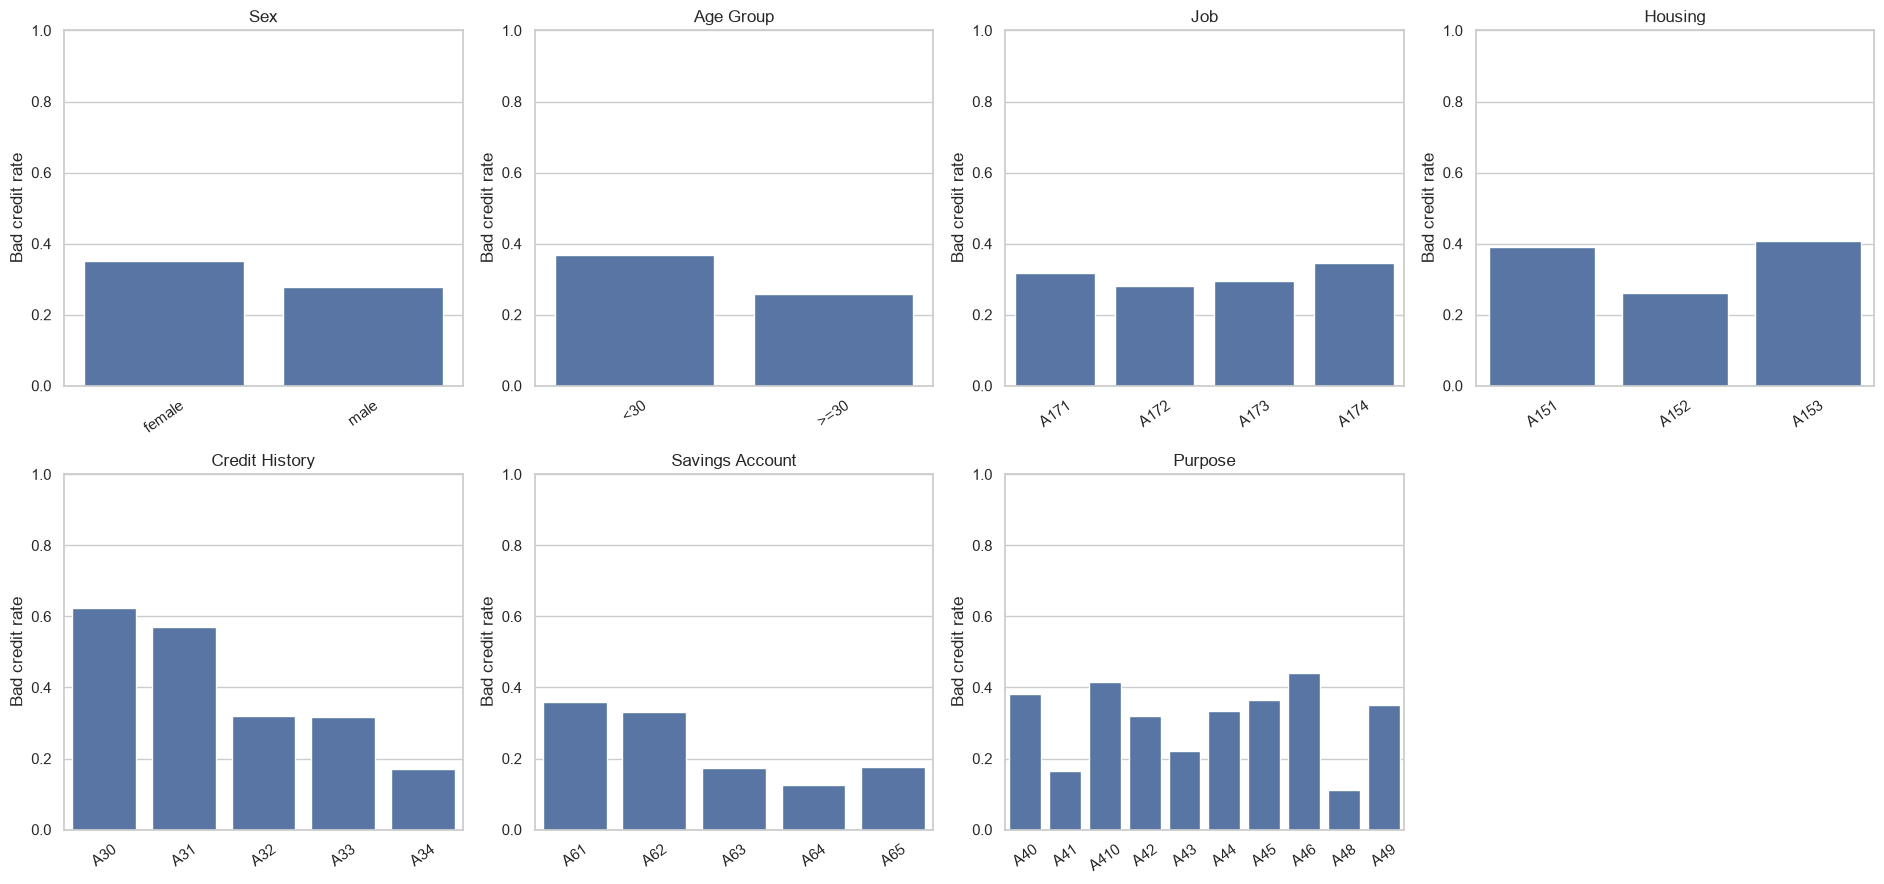

In [20]:
fig, axes = plt.subplots(2, 4, figsize=(19, 9))
axes = axes.flatten()

for ax, feature in zip(axes, selected_features):
    bad_rates = (
        df.groupby(feature, observed=True)["target_bad"]
        .mean()
        .reset_index()
    )

    sns.barplot(
        data=bad_rates,
        x=feature,
        y="target_bad",
        ax=ax,
    )

    ax.set_title(feature.replace("_", " ").title())
    ax.set_xlabel("")
    ax.set_ylabel("Bad credit rate")
    ax.set_ylim(0, 1)
    ax.tick_params(axis="x", rotation=35)

axes[-1].set_visible(False)

plt.tight_layout()
plt.show()

### Check group sizes before fairness evaluation

In [23]:
for feature in selected_features:
    counts = df[feature].value_counts()

    print(f"\n=== {feature} ===")
    print(pd.DataFrame({
        "total": counts,
        "expected_test_size": (counts * 0.2).round().astype(int),
    }))


=== sex ===
        total  expected_test_size
sex                              
male      690                 138
female    310                  62

=== age_group ===
           total  expected_test_size
age_group                           
>=30         629                 126
<30          371                  74

=== job ===
      total  expected_test_size
job                            
A173    630                 126
A172    200                  40
A174    148                  30
A171     22                   4

=== housing ===
         total  expected_test_size
housing                           
A152       713                 143
A151       179                  36
A153       108                  22

=== credit_history ===
                total  expected_test_size
credit_history                           
A32               530                 106
A34               293                  59
A33                88                  18
A31                49                  10
A30        

Inspect the distributions of both target classes inside each group.

In [24]:
for feature in selected_features:
    summary = pd.crosstab(
        df[feature],
        df["target_bad"],
    ).rename(columns={
        0: "good_credit",
        1: "bad_credit",
    })

    summary["expected_test_good"] = (
        summary["good_credit"] * 0.2
    ).round().astype(int)

    summary["expected_test_bad"] = (
        summary["bad_credit"] * 0.2
    ).round().astype(int)

    print(f"\n=== {feature} ===")
    print(summary)


=== sex ===
target_bad  good_credit  bad_credit  expected_test_good  expected_test_bad
sex                                                                       
female              201         109                  40                 22
male                499         191                 100                 38

=== age_group ===
target_bad  good_credit  bad_credit  expected_test_good  expected_test_bad
age_group                                                                 
<30                 234         137                  47                 27
>=30                466         163                  93                 33

=== job ===
target_bad  good_credit  bad_credit  expected_test_good  expected_test_bad
job                                                                       
A171                 15           7                   3                  1
A172                144          56                  29                 11
A173                444         186                  89

# Model Training

In [4]:
NUMERIC_FEATURES = [
    "duration_months",
    "credit_amount",
    "installment_rate",
    "residence_since",
    "existing_credits",
    "liable_people",
]

CATEGORICAL_FEATURES = [
    "checking_account",
    "credit_history",
    "purpose",
    "savings_account",
    "employment_since",
    "other_debtors",
    "property",
    "other_installment_plans",
    "housing",
    "job",
    "telephone",
    "foreign_worker",
]

MODEL_FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES

TARGET = "target_bad"

print("Numerical features:", len(NUMERIC_FEATURES))
print("Categorical features:", len(CATEGORICAL_FEATURES))
print("Total model features:", len(MODEL_FEATURES))

Numerical features: 6
Categorical features: 12
Total model features: 18


## Train/test split

In [5]:
from sklearn.model_selection import train_test_split

train_df, test_df = train_test_split(
    df,
    test_size=0.2,
    random_state=42,
    stratify=df[TARGET],
)

X_train = train_df[MODEL_FEATURES].copy()
X_test = test_df[MODEL_FEATURES].copy()

y_train = train_df[TARGET].copy()
y_test = test_df[TARGET].copy()

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting target distribution:")
print(y_test.value_counts().sort_index())

Training set: (800, 18)
Testing set: (200, 18)

Training target distribution:
target_bad
0    560
1    240
Name: count, dtype: int64

Testing target distribution:
target_bad
0    140
1     60
Name: count, dtype: int64


### Inspect the split
Verify the target distribution.

In [6]:
distribution = pd.DataFrame({
    "train": y_train.value_counts(normalize=True),
    "test": y_test.value_counts(normalize=True),
}).rename(index={
    0: "Good credit",
    1: "Bad credit",
})

print((distribution * 100).round(2))

             train  test
target_bad              
Good credit   70.0  70.0
Bad credit    30.0  30.0


In [16]:
GROUP_FEATURES = [
    ("sex",),
    ("age_group",),
    ("job", "job_label"),
    ("housing", "housing_label"),
    ("credit_history", "credit_history_label"),
    ("savings_account", "savings_account_label"),
    ("purpose", "purpose_label"),
]

for columns in GROUP_FEATURES:
    summary = (
        test_df.groupby(list(columns), observed=True)[TARGET]
        .value_counts()
        .unstack(fill_value=0)
        .reindex(columns=[0, 1], fill_value=0)
    )

    summary.columns = ["good_credit", "bad_credit"]
    summary["total"] = summary.sum(axis=1)
    summary["bad_credit_rate"] = summary["bad_credit"] / summary["total"]

    summary = summary.reset_index()

    print(f"\n=== {columns[0]} ===")
    print(summary.round(3).to_string(index=False))


=== sex ===
   sex  good_credit  bad_credit  total  bad_credit_rate
female           41          20     61            0.328
  male           99          40    139            0.288

=== age_group ===
age_group  good_credit  bad_credit  total  bad_credit_rate
      <30           45          34     79            0.430
     >=30           95          26    121            0.215

=== job ===
 job                                     job_label  good_credit  bad_credit  total  bad_credit_rate
A171         Unemployed / unskilled (non-resident)            5           1      6            0.167
A172                          Unskilled (resident)           32          10     42            0.238
A173                   Skilled employee / official           81          38    119            0.319
A174 Management / self-employed / highly qualified           22          11     33            0.333

=== housing ===
housing housing_label  good_credit  bad_credit  total  bad_credit_rate
   A151          Rent 

## Data Preprocessing
Dataset contains numerical and categorical features, and Logistic Regression works with numerical inputs.
We'll need two transformations:
- Scaled numerical features.
- Encoded categorical features.
- ColumnTransformer combines numerical and categorical transformations.

Important details:
- StandardScaler standardizes numerical features so that their scales are comparable.
- OneHotEncoder converts categorical values into binary columns.
- handle_unknown="ignore" prevents errors when the test set contains categories that were not encountered during training.

In [18]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

numeric_transformer = Pipeline(steps=[
    ("scaler", StandardScaler()),
])

categorical_transformer = Pipeline(steps=[
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, NUMERIC_FEATURES),
        ("cat", categorical_transformer, CATEGORICAL_FEATURES),
    ],
)

Combine preprocessing and Logistic Regression

In [20]:
from sklearn.linear_model import LogisticRegression

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42,
    )),
])

Verify the pipeline configuration

In [21]:
print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))
print("Model input features:", len(MODEL_FEATURES))

print("\nSensitive attributes in model inputs:")
print(set(["sex", "age_group", "age", "personal_status_sex"]) & set(MODEL_FEATURES))

print("\nProxy features in model inputs:")
print(set(["job", "housing", "credit_history", "savings_account", "purpose"]) & set(MODEL_FEATURES))

Training observations: 800
Testing observations: 200
Model input features: 18

Sensitive attributes in model inputs:
set()

Proxy features in model inputs:
{'credit_history', 'housing', 'savings_account', 'job', 'purpose'}


## Train Logistic Regression

In [22]:
model.fit(X_train, y_train)
print("Model training completed.")

Model training completed.


Generate predictions and probabilities (y_proba contains the predicted probabilities of bad credit).

In [24]:
y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]

Evaluate overall model performance

In [25]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
)

metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, pos_label=1),
    "Recall": recall_score(y_test, y_pred, pos_label=1),
    "F1-score": f1_score(y_test, y_pred, pos_label=1),
    "ROC-AUC": roc_auc_score(y_test, y_proba),
}

print("Overall model performance:")
for name, value in metrics.items():
    print(f"{name}: {value:.4f}")

print("\nClassification report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Good credit", "Bad credit"],
))

print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred, labels=[0, 1]))

Overall model performance:
Accuracy: 0.7850
Precision: 0.6735
Recall: 0.5500
F1-score: 0.6055
ROC-AUC: 0.8035

Classification report:
              precision    recall  f1-score   support

 Good credit       0.82      0.89      0.85       140
  Bad credit       0.67      0.55      0.61        60

    accuracy                           0.79       200
   macro avg       0.75      0.72      0.73       200
weighted avg       0.78      0.79      0.78       200

Confusion matrix:
[[124  16]
 [ 27  33]]


The ROC-AUC of 0.8035 indicates that the classifier has a reasonably good ability to distinguish between the two credit classes.

## Group-wise fairness evaluation

Attach predictions to the test DataFrame. This gives us one DataFrame containing the actual target, predicted target, predicted probability, and all demographic and proxy features.

In [29]:
evaluation_df = test_df.copy()

evaluation_df["y_true"] = y_test.to_numpy()
evaluation_df["y_pred"] = y_pred
evaluation_df["y_score"] = y_proba

The group metrics function calculates Accuracy, Precision, Recall, F1, Specifity, and ROC-AUC:
- actual_bad tells us how many actual bad-credit applicants are in the group.
- predicted_bad tells us how many applicants our model classified as bad credit.
- bad_credit_rate describes the actual target distribution.
- predicted_bad_rate describes the model's prediction distribution.

In [ ]:
GROUP_FEATURES = {
    "Sex": "sex",
    "Age group": "age_group",
    "Job": "job_label",
    "Housing": "housing_label",
    "Credit history": "credit_history_label",
    "Savings account": "savings_account_label",
    "Purpose": "purpose_label",
}

import numpy as np
from sklearn.metrics import confusion_matrix, roc_auc_score

def calculate_group_metrics(group):
    y_true = group["y_true"].to_numpy()
    y_pred = group["y_pred"].to_numpy()
    y_score = group["y_score"].to_numpy()

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1],
    ).ravel()

    total = len(group)
    accuracy = (tp + tn) / total
    precision = (
        tp / (tp + fp)
        if tp + fp > 0
        else np.nan
    )
    recall = (
        tp / (tp + fn)
        if tp + fn > 0
        else np.nan
    )
    specificity = (
        tn / (tn + fp)
        if tn + fp > 0
        else np.nan
    )
    f1 = (
        2 * tp / (2 * tp + fp + fn)
        if 2 * tp + fp + fn > 0
        else np.nan
    )
    roc_auc = (
        roc_auc_score(y_true, y_score)
        if len(np.unique(y_true)) == 2
        else np.nan
    )
    return {
        "total": total,
        "actual_good": tn + fp,
        "actual_bad": tp + fn,
        "predicted_bad": tp + fp,
        "bad_credit_rate": (tp + fn) / total,
        "predicted_bad_rate": (tp + fp) / total,
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "specificity": specificity,
        "f1": f1,
        "roc_auc": roc_auc,
        "tp": tp,
        "fp": fp,
        "tn": tn,
        "fn": fn,
    }

Calculate metrics for every group.

In [32]:
group_results = []

for feature_name, column in GROUP_FEATURES.items():
    for group_value, group_data in evaluation_df.groupby(
        column,
        observed=True,
        dropna=False,
    ):
        metrics = calculate_group_metrics(group_data)

        group_results.append({
            "feature": feature_name,
            "group": str(group_value),
            **metrics,
        })

group_metrics = pd.DataFrame(group_results)

for feature_name in GROUP_FEATURES:
    print(f"\n=== {feature_name} ===")

    result = group_metrics[
        group_metrics["feature"] == feature_name
    ].drop(columns=["feature"])

    print(result.round(3).to_string(index=False))


=== Sex ===
 group  total  actual_good  actual_bad  predicted_bad  bad_credit_rate  predicted_bad_rate  accuracy  precision  recall  specificity    f1  roc_auc
female     61           41          20             17            0.328               0.279     0.754      0.647    0.55        0.854 0.595    0.826
  male    139           99          40             32            0.288               0.230     0.799      0.688    0.55        0.899 0.611    0.795

=== Age group ===
group  total  actual_good  actual_bad  predicted_bad  bad_credit_rate  predicted_bad_rate  accuracy  precision  recall  specificity    f1  roc_auc
  <30     79           45          34             25            0.430               0.316     0.734      0.760   0.559        0.867 0.644    0.770
 >=30    121           95          26             24            0.215               0.198     0.818      0.583   0.538        0.895 0.560    0.819

=== Job ===
                                        group  total  actual_good  act

Compare performance visually.

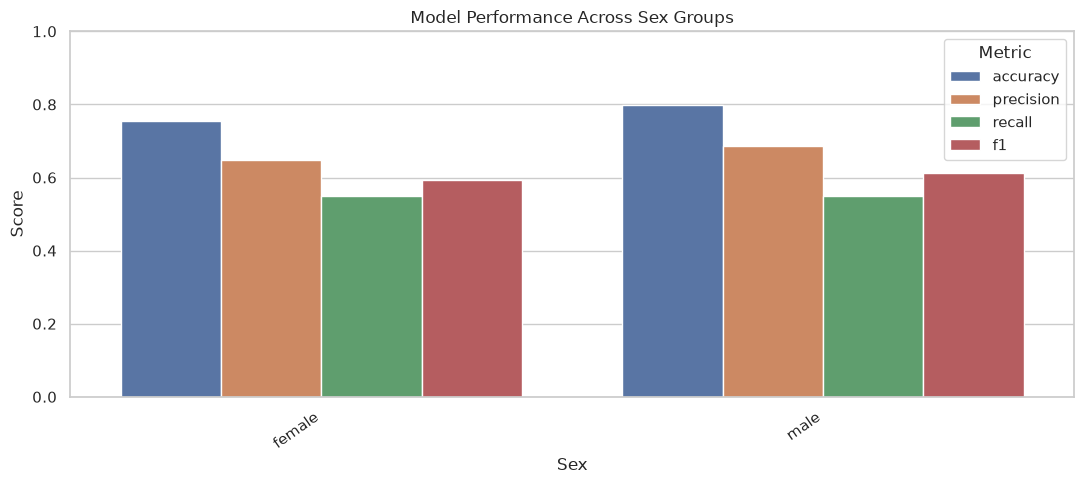

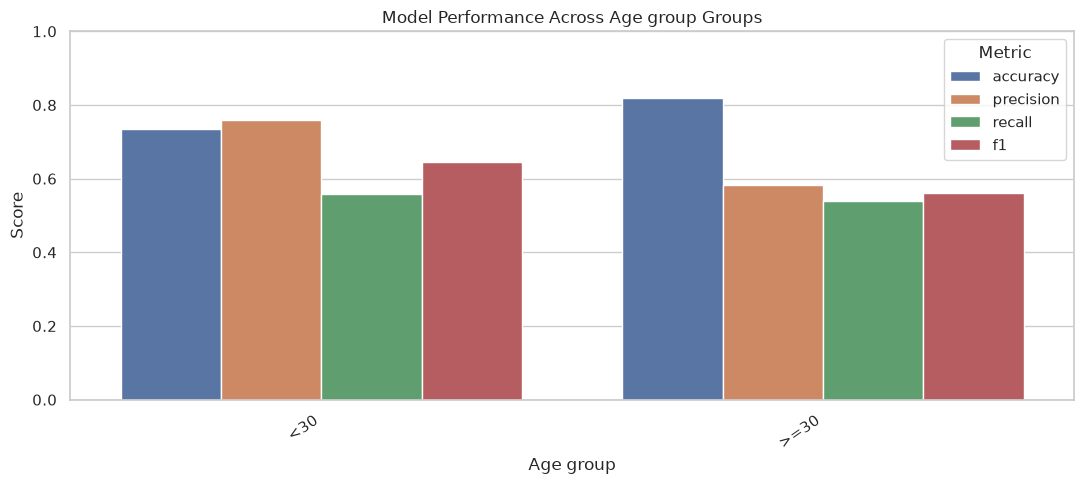

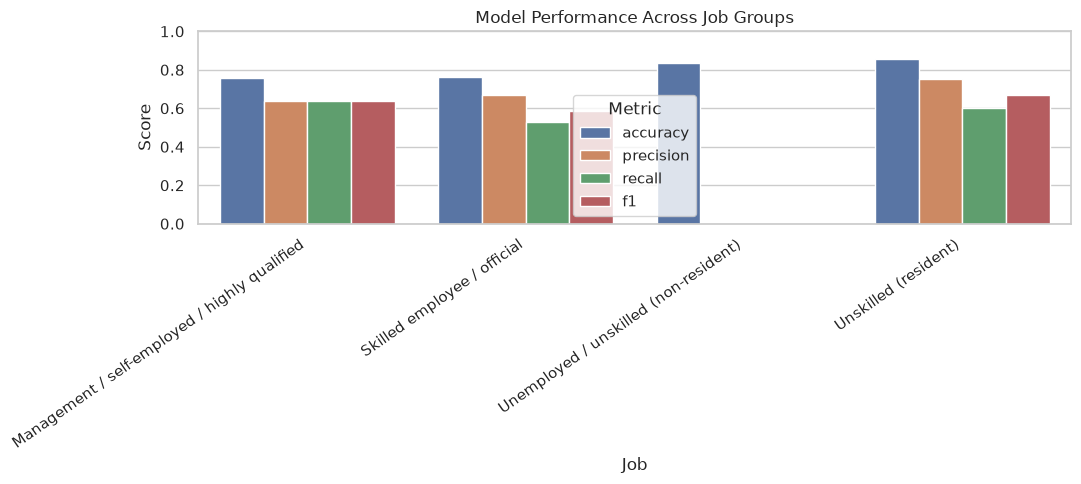

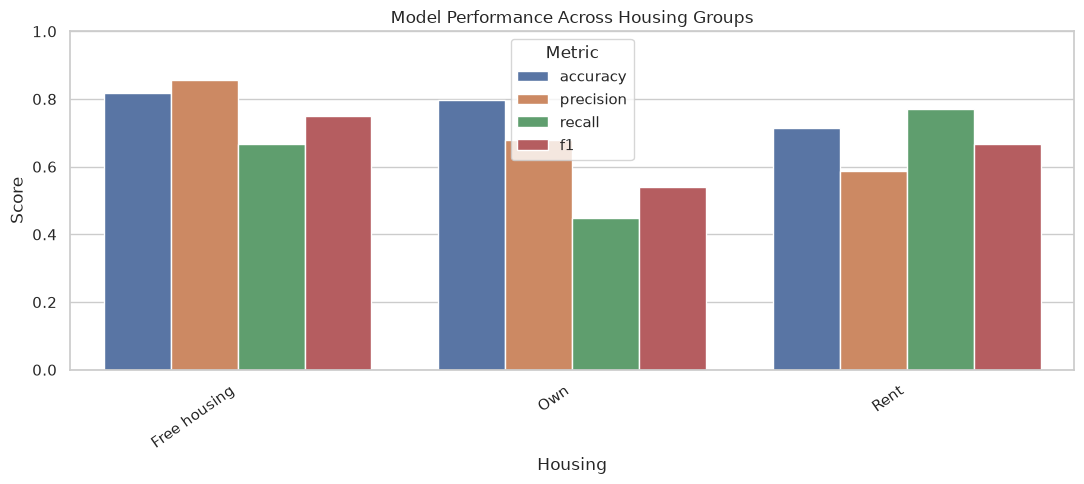

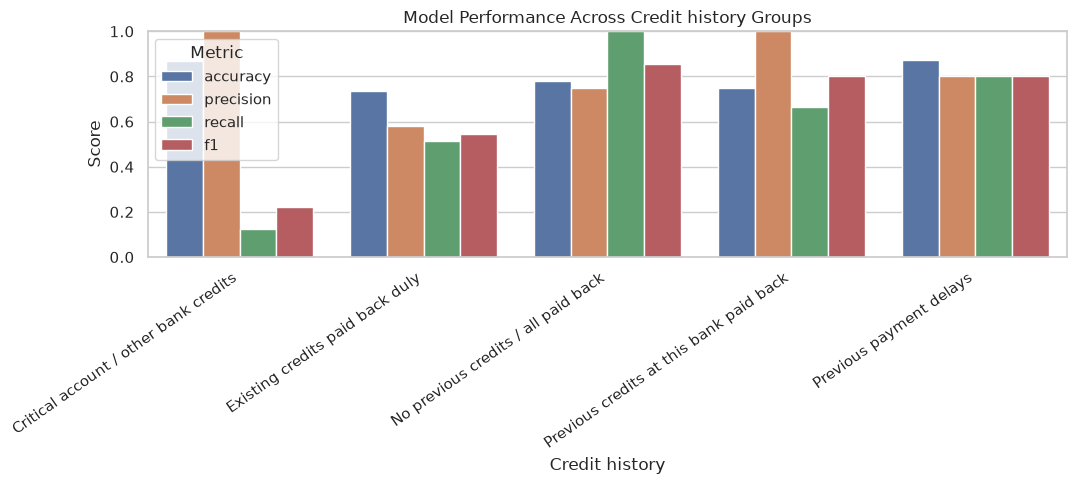

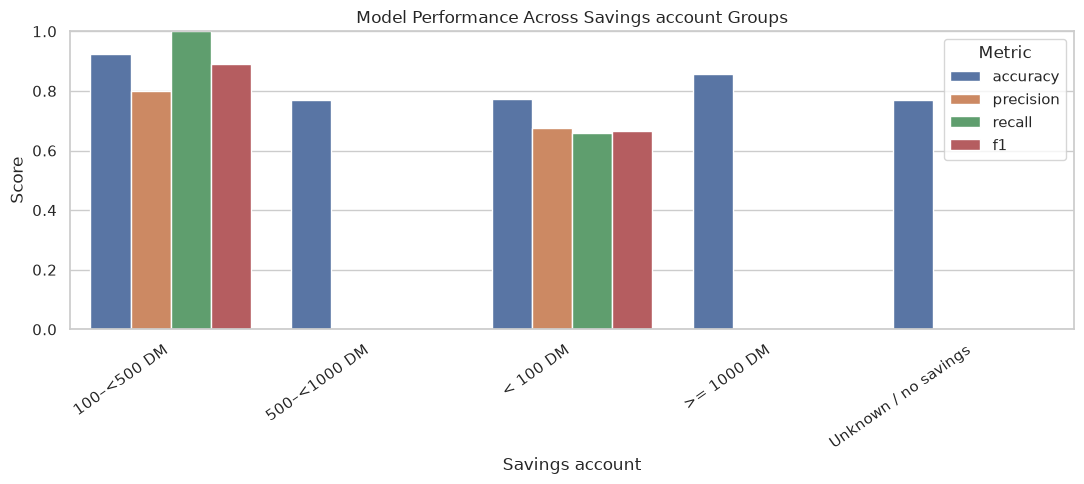

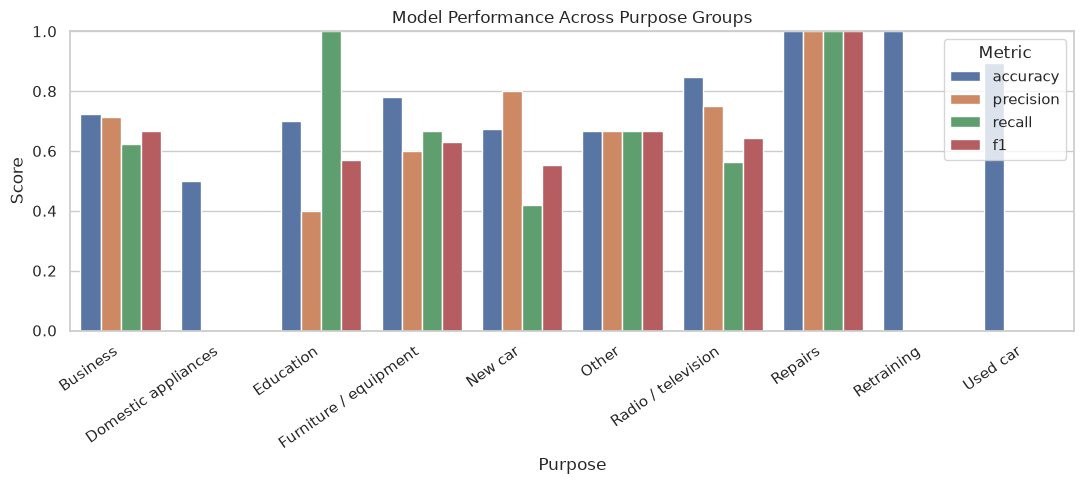

In [33]:
METRICS = [
    "accuracy",
    "precision",
    "recall",
    "f1",
]
for feature_name in GROUP_FEATURES:
    result = group_metrics[
        group_metrics["feature"] == feature_name
    ]
    melted = result.melt(
        id_vars="group",
        value_vars=METRICS,
        var_name="metric",
        value_name="score",
    )
    plt.figure(figsize=(11, 5))
    sns.barplot(
        data=melted,
        x="group",
        y="score",
        hue="metric",
    )
    plt.title(f"Model Performance Across {feature_name} Groups")
    plt.xlabel(feature_name)
    plt.ylabel("Score")
    plt.ylim(0, 1)
    plt.xticks(rotation=35, ha="right")
    plt.legend(title="Metric")
    plt.tight_layout()
    plt.show()

### Quantifying fairness gaps
We've calculated performance metrics for every group. The next step is to summarize the differences numerically.

In [36]:
# Calculate the false positive rate
group_metrics["fpr"] = 1 - group_metrics["specificity"]

# Create a summary function
def calculate_group_gaps(group_metrics, min_class_support=5):
    results = []
    metrics = {
        "Accuracy gap": "accuracy",
        "Recall gap (Equal Opportunity)": "recall",
        "FPR gap": "fpr",
        "Predicted bad-rate gap": "predicted_bad_rate",
        "ROC-AUC gap": "roc_auc",
    }
    for feature in group_metrics["feature"].unique():
        subset = group_metrics[
            group_metrics["feature"] == feature
        ]
        # Exclude groups with insufficient representation
        # of either actual target class.
        subset = subset[
            (subset["actual_good"] >= min_class_support)
            & (subset["actual_bad"] >= min_class_support)
        ]
        for metric_name, column in metrics.items():
            values = subset.dropna(subset=[column])
            if len(values) < 2:
                continue
            min_row = values.loc[values[column].idxmin()]
            max_row = values.loc[values[column].idxmax()]
            results.append({
                "feature": feature,
                "metric": metric_name,
                "min_group": min_row["group"],
                "min_value": min_row[column],
                "max_group": max_row["group"],
                "max_value": max_row[column],
                "gap_pp": (
                    max_row[column] - min_row[column]
                ) * 100,
                "groups_compared": len(values),
            })

    return pd.DataFrame(results)

# Run the function
gap_summary = calculate_group_gaps(group_metrics)

print(
    gap_summary.round(2).to_string(index=False)
)

        feature                         metric                                     min_group  min_value                                     max_group  max_value  gap_pp  groups_compared
            Sex                   Accuracy gap                                        female       0.75                                          male       0.80    4.45                2
            Sex Recall gap (Equal Opportunity)                                        female       0.55                                        female       0.55    0.00                2
            Sex                        FPR gap                                          male       0.10                                        female       0.15    4.53                2
            Sex         Predicted bad-rate gap                                          male       0.23                                        female       0.28    4.85                2
            Sex                    ROC-AUC gap                        

Add 95% Wilson confidence intervals for Recall and FPR.

This will help us distinguish a large observed difference from an estimate that is highly uncertain because of limited observations.

In [29]:
from math import sqrt

def wilson_interval(successes, total, z=1.96):
    if total == 0:
        return np.nan, np.nan

    p = successes / total
    denominator = 1 + z**2 / total

    center = (p + z**2 / (2 * total)) / denominator
    margin = (
        z * sqrt(p * (1 - p) / total + z**2 / (4 * total**2))
        / denominator
    )

    return center - margin, center + margin

def add_confidence_intervals(results):
    results = results.copy()

    for metric, successes_col, total_col in [
        ("recall", "tp", "actual_bad"),
        ("fpr", "fp", "actual_good"),
    ]:
        intervals = results.apply(
            lambda row: wilson_interval(
                row[successes_col],
                row[total_col],
            ),
            axis=1,
        )

        results[f"{metric}_ci_lower"] = [x[0] for x in intervals]
        results[f"{metric}_ci_upper"] = [x[1] for x in intervals]

    return results


group_metrics = add_confidence_intervals(group_metrics)

for feature in ["sex", "age_group", "housing_label", "savings_account_label"]:
    result = group_metrics[
        group_metrics["feature"].map({
            "Sex": "sex",
            "Age group": "age_group",
            "Housing": "housing_label",
            "Savings account": "savings_account_label",
        }) == feature
    ]

    print(f"\n=== {feature} ===")
    print(result[[
        "group", "actual_bad",
        "recall", "recall_ci_lower", "recall_ci_upper",
        "fpr", "fpr_ci_lower", "fpr_ci_upper",
    ]].round(3).to_string(index=False))


=== sex ===
 group  actual_bad  recall  recall_ci_lower  recall_ci_upper   fpr  fpr_ci_lower  fpr_ci_upper
female          20    0.55            0.342            0.742 0.146         0.069         0.284
  male          40    0.55            0.398            0.693 0.101         0.056         0.176

=== age_group ===
group  actual_bad  recall  recall_ci_lower  recall_ci_upper   fpr  fpr_ci_lower  fpr_ci_upper
  <30          34   0.559            0.395            0.711 0.133         0.063         0.262
 >=30          26   0.538            0.355            0.712 0.105         0.058         0.183

=== housing_label ===
       group  actual_bad  recall  recall_ci_lower  recall_ci_upper   fpr  fpr_ci_lower  fpr_ci_upper
Free housing           9   0.667            0.354            0.879 0.077         0.014         0.333
         Own          38   0.447            0.301            0.603 0.076         0.039         0.143
        Rent          13   0.769            0.497            0.918 0.318   

Calculate bootstrap confidence intervals for the principal group differences, particularly Housing's FPR and Recall gaps.

For Recall, we'll resample only applicants with y_true = 1. For FPR, we'll resample only applicants with y_true = 0. This keeps the denominator appropriate for each metric and avoids bootstrap samples with undefined rates.

In [30]:
def bootstrap_rate_difference(
    data,
    feature,
    group_a,
    group_b,
    metric,
    n_boot=20_000,
    rng=None,
):
    if metric == "recall":
        actual_class = 1
    elif metric == "fpr":
        actual_class = 0
    else:
        raise ValueError("metric must be 'recall' or 'fpr'")

    if rng is None:
        rng = np.random.default_rng(42)

    def get_outcomes(group):
        subset = data[
            (data[feature] == group)
            & (data["y_true"] == actual_class)
        ]

        if subset.empty:
            raise ValueError(
                f"No observations for {group} "
                f"with actual class {actual_class}"
            )

        return subset["y_pred"].eq(1).to_numpy(dtype=np.int8)

    values_a = get_outcomes(group_a)
    values_b = get_outcomes(group_b)

    rate_a = values_a.mean()
    rate_b = values_b.mean()

    # Independently resample observations within each group.
    boot_a = rng.choice(
        values_a,
        size=(n_boot, len(values_a)),
        replace=True,
    ).mean(axis=1)

    boot_b = rng.choice(
        values_b,
        size=(n_boot, len(values_b)),
        replace=True,
    ).mean(axis=1)

    differences = boot_a - boot_b

    ci_lower, ci_upper = np.quantile(
        differences,
        [0.025, 0.975],
    )

    return {
        "feature": feature,
        "metric": metric,
        "comparison": f"{group_a} - {group_b}",
        "n_a": len(values_a),
        "n_b": len(values_b),
        "rate_a": rate_a,
        "rate_b": rate_b,
        "difference_pp": (rate_a - rate_b) * 100,
        "ci_lower_pp": ci_lower * 100,
        "ci_upper_pp": ci_upper * 100,
    }

rng = np.random.default_rng(42)

comparisons = []

for metric in ["recall", "fpr"]:
    result = bootstrap_rate_difference(
        data=evaluation_df,
        feature="housing_label",
        group_a="Rent",
        group_b="Own",
        metric=metric,
        n_boot=20_000,
        rng=rng,
    )

    comparisons.append(result)

bootstrap_results = pd.DataFrame(comparisons)

print(
    bootstrap_results.round(2).to_string(index=False)
)

      feature metric comparison  n_a  n_b  rate_a  rate_b  difference_pp  ci_lower_pp  ci_upper_pp
housing_label recall Rent - Own   13   38    0.77    0.45          32.19         3.64        58.10
housing_label    fpr Rent - Own   22  105    0.32    0.08          24.20         4.85        45.02


Visualize the bootstrap confidence intervals

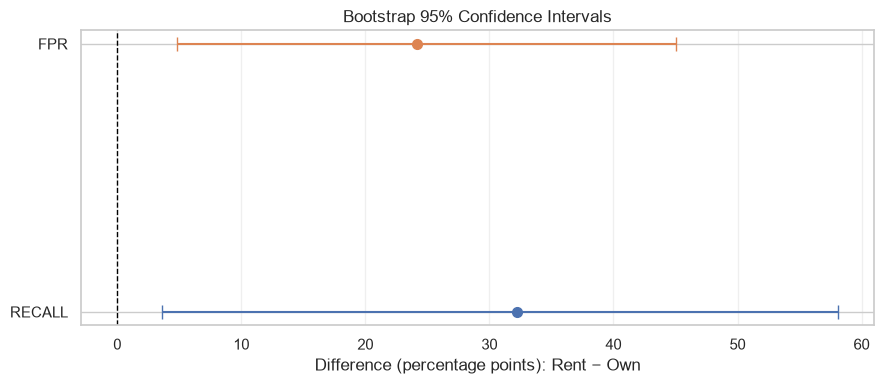

In [31]:
fig, ax = plt.subplots(figsize=(9, 4))

for i, row in bootstrap_results.reset_index(drop=True).iterrows():
    ax.errorbar(
        x=row["difference_pp"],
        y=i,
        xerr=[[
            row["difference_pp"] - row["ci_lower_pp"]
        ], [
            row["ci_upper_pp"] - row["difference_pp"]
        ]],
        fmt="o",
        capsize=5,
        markersize=7,
    )

ax.axvline(0, linestyle="--", linewidth=1, color="black")

ax.set_yticks(range(len(bootstrap_results)))
ax.set_yticklabels(bootstrap_results["metric"].str.upper())
ax.set_xlabel("Difference (percentage points): Rent − Own")
ax.set_title("Bootstrap 95% Confidence Intervals")
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

**Housing-related performance disparity**: Applicants who rent experience a substantially higher false positive rate than applicants who own their homes (31.8% versus 7.6%). The estimated difference is 24.2 percentage points, with a 95% bootstrap confidence interval of 4.85–45.02 percentage points. Rent applicants also have higher Recall (76.9% versus 44.7%), with a bootstrap difference of 32.19 percentage points (95% CI: 3.64–58.10).

These findings suggest that the model's classification errors are not distributed equally across housing groups. In a credit-lending application, the higher false positive rate could disadvantage creditworthy renters through unjustified risk classification or loan rejection.